# 01 · Ingesta, auditoría de códigos centinela y diseño muestral complejo (ENEMDU 2025)

Auditamos los microdatos anuales de la **Encuesta Nacional de Empleo, Desempleo y Subempleo (ENEMDU 2025)** del INEC, cuantificamos el sesgo de no limpiar los códigos centinela (`999999` y `-1` en ingresos laborales) y comprobamos que el estimador por linealización de Taylor **coincide con el tabulado oficial del INEC dentro del redondeo a un decimal**. Todas las cifras de este cuaderno se leen de `reports/`.

In [1]:
import json
import pandas as pd
from empleo_enemdu.config import DIR_PROCESADOS, DIR_REPORTS, DIR_TABLAS
from empleo_enemdu.encuesta import DisenoMuestralENEMDU, estimar_razon_dominio

res = json.loads((DIR_REPORTS / "resultados.json").read_text(encoding="utf-8"))
calidad = res["calidad_y_diseno"]
print("Resumen del marco muestral ENEMDU Anual 2025:")
for k, v in calidad.items():
    if k != "centinelas_detectados":
        print(f"  - {k}: {v:,}" if isinstance(v, (int, float)) else f"  - {k}: {v}")

Resumen del marco muestral ENEMDU Anual 2025:
  - filas_totales_personas: 334,786
  - hogares_unicos: 104,738
  - viviendas_unicas: 104,333
  - upm_unicas: 7,780
  - estratos_unicos: 150
  - poblacion_total_expandida: 18,855,042.27
  - pet_expandida: 13,400,116.63
  - pea_expandida: 8,612,073.19
  - ocupados_expandidos: 8,304,521.98


## 1. Auditoría de códigos centinela en ingresos laborales (`ingrl`)

En la base abierta, `999999` identifica a ocupados que no informan su ingreso y `-1` a ocupados sin ingreso monetario. Promediar la columna cruda infla el ingreso laboral medio; la celda siguiente muestra cuánto.

In [2]:
centinelas = pd.DataFrame([calidad["centinelas_detectados"]])
cen = calidad["centinelas_detectados"]
print(
    f"Media cruda: {cen['media_ingrl_cruda_sin_limpiar_usd']:,.2f} USD · media limpia ponderada: "
    f"{cen['media_ingrl_limpia_ponderada_usd']:,.2f} USD · factor: {cen['factor_distorsion_centinela']}x"
)
centinelas

Media cruda: 3,840.42 USD · media limpia ponderada: 498.97 USD · factor: 7.7x


,ingrl_999999_no_informa,ingrl_menos_1_sin_ingreso,horas_999_no_informa,edad_99_tope,media_ingrl_cruda_sin_limpiar_usd,media_ingrl_limpia_ponderada_usd,factor_distorsion_centinela
0,480,1471,0,0,3840.42,498.97,7.7


## 2. Coincidencia con el tabulado oficial del INEC (80 celdas)

`DisenoMuestralENEMDU` implementa el estimador de razón para dominios con varianza por linealización de Taylor sobre `estrato = plan_muestreo`, `upm = id_sector` y `fexp`. Comparamos estimación y error estándar con el tabulado oficial **redondeando ambos a un decimal**, que es la precisión con la que publica el INEC.

In [3]:
df_rec = pd.read_csv(DIR_TABLAS / "reconciliacion_inec_2025.csv")
print(f"Celdas auditadas (10 indicadores x 8 dominios): {len(df_rec)} · coinciden: {int(df_rec['reconcilia_ok'].sum())}")
print(f"Diferencia máxima tras redondear a 1 decimal, estimación (pp): {df_rec['dif_indicador_pp'].abs().max():.1f}")
print(f"Diferencia máxima tras redondear a 1 decimal, error estándar (pp): {df_rec['dif_ee_pp'].abs().max():.1f}")
df_rec.loc[
    df_rec["dominio"] == "Total",
    [
        "indicador",
        "estimacion_pct",
        "indicador_oficial_pct",
        "ee_complejo_pct",
        "ee_mas_pct",
        "deff",
        "deft",
        "sesgo_sin_ponderar_pp",
    ],
]

Celdas auditadas (10 indicadores x 8 dominios): 80 · coinciden: 80
Diferencia máxima tras redondear a 1 decimal, estimación (pp): 0.0
Diferencia máxima tras redondear a 1 decimal, error estándar (pp): 0.0


,indicador,estimacion_pct,indicador_oficial_pct,ee_complejo_pct,ee_mas_pct,deff,deft,sesgo_sin_ponderar_pp
0,Empleo Bruto,61.9735,62.0,0.4418,0.0940,22.11,4.70,-1.3093
8,Empleo Global,96.4288,96.4,0.1281,0.0451,8.07,2.84,-0.8781
16,Empleo Adecuado/Pleno,37.1295,37.1,0.5910,0.1174,25.36,5.04,4.6080
24,Subempleo,19.4151,19.4,0.3582,0.0961,13.89,3.73,-2.2680
32,Empleo no Remunerado,8.8153,8.8,0.4604,0.0689,44.68,6.68,-0.8251
40,Otro Empleo no pleno,30.8425,30.8,0.4886,0.1122,18.96,4.35,-2.4321
48,Desempleo,3.5712,3.6,0.1281,0.0451,8.07,2.84,0.8781
56,Participación Global,64.2686,64.3,0.4575,0.0928,24.33,4.93,-0.7797
64,Participación Bruta,45.6752,45.7,0.4590,0.0861,28.43,5.33,4.9378
72,Sector informal,51.4874,51.5,0.8053,0.1242,42.03,6.48,-7.7750


## 3. Verificación directa con `DisenoMuestralENEMDU`

Calculamos en vivo el empleo adecuado y la informalidad nacionales para ver la inflación del error estándar (`DEFT = √DEFF`) por la correlación dentro de los sectores censales. Si el parquet completo no está (no se versiona en Git), se usa la muestra de 120 UPM de `data/muestra/`, con estimaciones menos precisas.

In [4]:
from empleo_enemdu.config import DIR_MUESTRA

ruta_pet = DIR_PROCESADOS / "enemdu_pet_2025.parquet"
if not ruta_pet.exists():
    print("Parquet completo no encontrado: se usa la muestra de 120 UPM (ejecuta el pipeline para la base completa).")
    ruta_pet = DIR_MUESTRA / "muestra_enemdu_2025.parquet"
df_pet = pd.read_parquet(ruta_pet)
diseno = DisenoMuestralENEMDU.desde_dataframe(df_pet)
est_adec = estimar_razon_dominio(diseno, df_pet["adec"], df_pet["pean"].eq(1), indicador="Empleo Adecuado/Pleno")
est_inf = estimar_razon_dominio(diseno, df_pet["informal"], df_pet["empleo_ind"].eq(1), indicador="Sector informal")
pd.DataFrame([est_adec.a_dict(en_porcentaje=True), est_inf.a_dict(en_porcentaje=True)])[
    ["indicador", "estimacion", "error_estandar", "error_estandar_mas", "limite_inferior", "limite_superior", "deff", "deft", "n_upm"]
]

,indicador,estimacion,error_estandar,error_estandar_mas,limite_inferior,limite_superior,deff,deft,n_upm
0,Empleo Adecuado/Pleno,37.1295,0.5910,0.1174,35.9709,38.288,25.355178,5.035393,7780
1,Sector informal,51.4874,0.8053,0.1242,49.9088,53.066,42.034015,6.483364,7780


## 4. Figura: efecto de `fexp` y del diseño en las tasas y los errores estándar

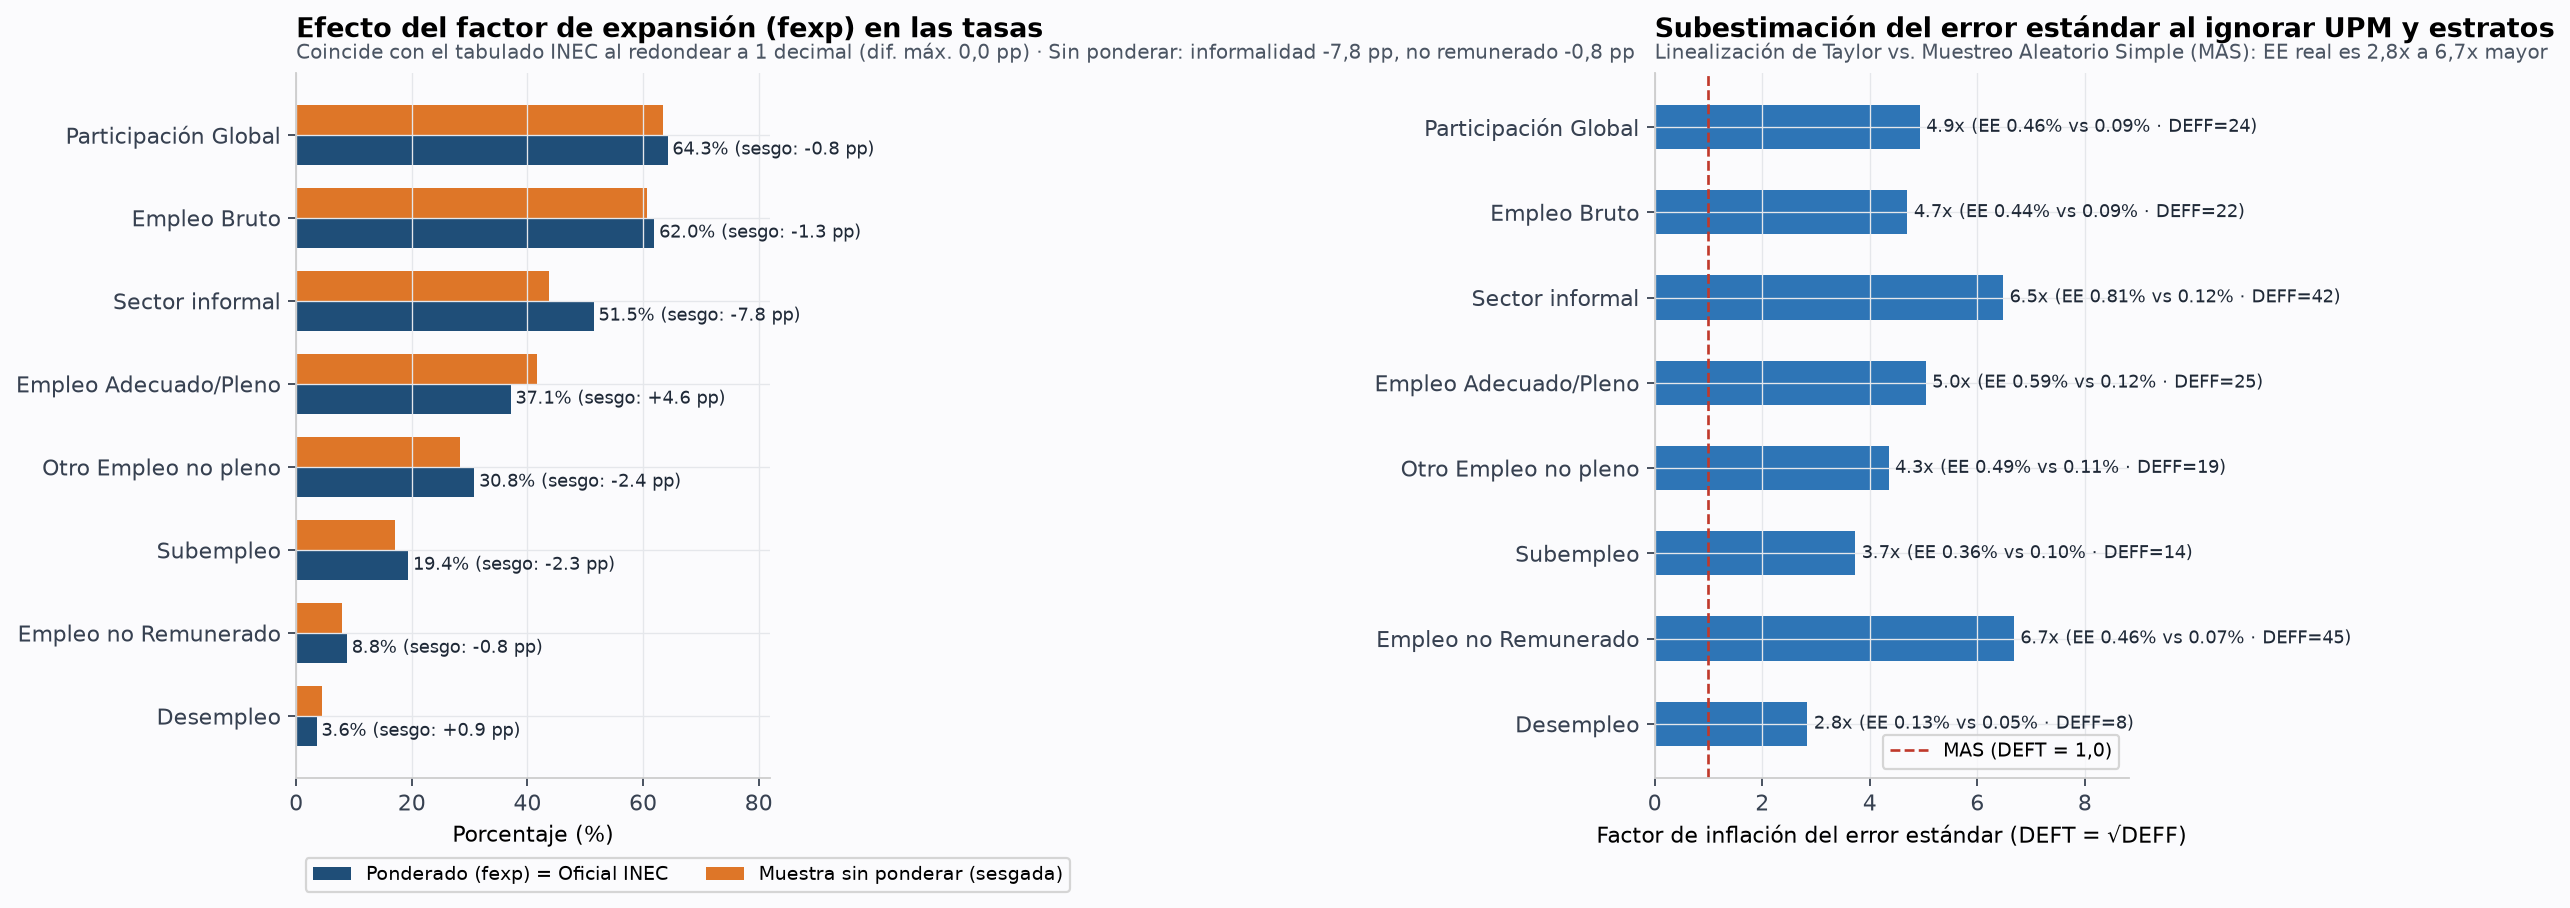

In [5]:
import tempfile
from pathlib import Path
from IPython.display import Image, display
from empleo_enemdu import graficos

# Las figuras se regeneran aquí desde los datos (en una carpeta temporal) y se muestran en línea
DIR_TMP = Path(tempfile.mkdtemp())

display(Image(filename=graficos.fig_01_diseno_muestral_y_reconciliacion(df_rec, DIR_TMP)))

## 5. Validación con microdatos 2024

La serie 2018–2025 que usa el proyecto es la **publicada por el INEC**. Para comprobar que el mismo código reproduce otro año, `python -m empleo_enemdu.validacion_anual --anio 2024` recalcula 2024 con microdatos y lo compara con la serie oficial.

In [6]:
val24 = json.loads((DIR_REPORTS / "validacion_microdatos_2024.json").read_text(encoding="utf-8"))
print(f"2024: {val24['celdas_coinciden']}/{val24['celdas_comparadas']} celdas coinciden (dif. máx. {val24['dif_max_abs_pp']} pp)")
pd.DataFrame(val24["nacional"]).T

2024: 80/80 celdas coinciden (dif. máx. 0.0 pp)


,calculado_pct,serie_inec_pct
Empleo Bruto,61.85,61.8
Empleo Global,96.25,96.3
Empleo Adecuado/Pleno,35.88,35.9
Subempleo,21.02,21.0
Empleo no Remunerado,9.45,9.5
Otro Empleo no pleno,29.76,29.8
Desempleo,3.75,3.7
Participación Global,64.26,64.3
Participación Bruta,45.67,45.7
Sector informal,52.37,52.4
